## 1. Thuật toán SRG: Lazy / Frozen / Boundary / Frames

In [5]:
import heapq
import itertools
import numpy as np


def _neighbors(connectivity):
    if connectivity == 4:
        return ((-1, 0), (1, 0), (0, -1), (0, 1))
    if connectivity == 8:
        return ((-1, 0), (1, 0), (0, -1), (0, 1),
                (-1, -1), (-1, 1), (1, -1), (1, 1))
    raise ValueError('connectivity phải là 4 hoặc 8')


def _prepare(img, seeds):
    pixels = np.asarray(img, dtype=np.float64)
    if pixels.ndim == 2:
        pixels = pixels[:, :, None]
    if pixels.ndim != 3 or pixels.shape[2] == 0:
        raise ValueError('img phải có dạng (H,W) hoặc (H,W,C)')
    if not np.isfinite(pixels).all():
        raise ValueError('img không được chứa NaN/inf')
    H, W, C = pixels.shape
    try:
        seed_list = [tuple(map(int, s[:2])) for s in seeds]
    except (TypeError, ValueError) as e:
        raise ValueError('seeds phải là [(row,col), ...]') from e
    if not seed_list or len(set(seed_list)) != len(seed_list):
        raise ValueError('seeds cần khác nhau và không rỗng')
    if any(not (0 <= r < H and 0 <= c < W) for r, c in seed_list):
        raise ValueError('seed nằm ngoài ảnh')
    return pixels, seed_list


def make_boundary_mask(labels, connectivity=4):
    """Đánh dấu cả hai phía của mỗi cạnh nối 2 pixel mang nhãn khác nhau."""
    _neighbors(connectivity)
    b = np.zeros_like(labels, dtype=bool)
    offsets = [(1, 0), (0, 1)]
    if connectivity == 8:
        offsets += [(1, 1), (1, -1)]
    H, W = labels.shape
    for dr, dc in offsets:
        r0 = slice(max(0, -dr), min(H, H-dr))
        c0 = slice(max(0, -dc), min(W, W-dc))
        r1 = slice(max(0, dr), min(H, H+dr))
        c1 = slice(max(0, dc), min(W, W+dc))
        change = labels[r0, c0] != labels[r1, c1]
        b[r0, c0] |= change
        b[r1, c1] |= change
    return b


def srg(img, seeds, connectivity=4, stale='lazy', tie='insertion',
        random_seed=42, epsilon=1e-6, return_frames=False, n_frames=8):
    """Seeded Region Growing dùng heap; mọi pixel sẽ được gán cho một seed.

    frozen: ưu tiên khoảng cách tới seed gốc cố định, không cập nhật khi pop.
    lazy: ưu tiên khoảng cách tới mean vùng, kiểm lại khi pop và re-heap nếu cũ.
    """
    pixels, seeds = _prepare(img, seeds)
    offsets = _neighbors(connectivity)
    if stale not in ('lazy', 'frozen'):
        raise ValueError("stale phải là 'lazy' hoặc 'frozen'")
    if tie not in ('insertion', 'raster', 'random'):
        raise ValueError("tie phải là 'insertion', 'raster' hoặc 'random'")
    if epsilon < 0:
        raise ValueError('epsilon phải >= 0')
    if return_frames and n_frames < 2:
        raise ValueError('n_frames phải >= 2')

    H, W, C = pixels.shape
    k = len(seeds)
    labels = np.full((H, W), -1, dtype=np.int32)
    seeds_v = np.stack([pixels[r, c].copy() for r, c in seeds])
    sums = seeds_v.copy()
    counts = np.ones(k, dtype=np.int64)
    for rid, (r, c) in enumerate(seeds):
        labels[r, c] = rid

    rng = np.random.default_rng(random_seed)
    heap = []
    seq = itertools.count()

    def put(r, c, rid, delta=None):
        if delta is None:
            base = seeds_v[rid] if stale == 'frozen' else sums[rid] / counts[rid]
            delta = float(np.linalg.norm(pixels[r, c] - base))
        serial = next(seq)
        tie_val = serial if tie == 'insertion' else (r*W+c if tie == 'raster' else float(rng.random()))
        heapq.heappush(heap, (delta, tie_val, serial, r, c, rid))

    for rid, (r, c) in enumerate(seeds):
        for dr, dc in offsets:
            rr, cc = r + dr, c + dc
            if 0 <= rr < H and 0 <= cc < W and labels[rr, cc] < 0:
                put(rr, cc, rid)

    frames = []
    accepted = 0
    targets = (np.linspace(0, H*W-k, n_frames).round().astype(int)
               if return_frames else None)
    if return_frames:
        while len(frames) < n_frames and targets[len(frames)] == 0:
            frames.append(labels.copy())

    while heap:
        delta, _, _, r, c, rid = heapq.heappop(heap)
        if labels[r, c] != -1:
            continue
        if stale == 'lazy':
            fresh = float(np.linalg.norm(pixels[r, c] - sums[rid] / counts[rid]))
            if abs(fresh - delta) > epsilon:
                put(r, c, rid, fresh)
                continue
        # frozen: tuyệt đối KHÔNG cập nhật delta đã lưu trong heap.
        labels[r, c] = rid
        sums[rid] += pixels[r, c]
        counts[rid] += 1
        accepted += 1

        if return_frames:
            while len(frames) < n_frames and accepted >= targets[len(frames)]:
                frames.append(labels.copy())

        for dr, dc in offsets:
            rr, cc = r + dr, c + dc
            if 0 <= rr < H and 0 <= cc < W and labels[rr, cc] == -1:
                put(rr, cc, rid)

    if np.any(labels == -1):
        raise RuntimeError('Một số pixel chưa được gán nhãn; kiểm tra heap và connectivity')
    boundary = make_boundary_mask(labels, connectivity)
    if return_frames:
        while len(frames) < n_frames:
            frames.append(labels.copy())
        return labels, boundary, frames
    return labels, boundary


def srg_step_frames(img, seeds, n_frames=8, *, connectivity=4,
                    stale='lazy', tie='insertion', random_seed=42):
    """Trả list dài n_frames, mỗi phần tử là ma trận nhãn (H,W) có thể còn -1."""
    _, _, frames = srg(img, seeds, connectivity=connectivity, stale=stale,
                       tie=tie, random_seed=random_seed,
                       return_frames=True, n_frames=n_frames)
    return frames


## 2. A2/A3 — Boundary và tính tái lập ngẫu nhiên

In [6]:
import numpy as np
import matplotlib.pyplot as plt
flat_smoke = np.full((30, 40), 128.0)
smoke_seeds = [(15, 4), (15, 35)]
lab_a, boundary_a = srg(flat_smoke, smoke_seeds, tie='random', random_seed=100)
lab_b, boundary_b = srg(flat_smoke, smoke_seeds, tie='random', random_seed=100)
assert np.array_equal(lab_a, lab_b), 'tie=random phải tái lập với cùng seed'
assert np.array_equal(boundary_a, make_boundary_mask(lab_a, 4))
assert boundary_a.any(), 'boundary_mask phải xác định được biên'
print('A2/A3 PASS: boundary thật và random tái lập')


A2/A3 PASS: boundary thật và random tái lập


## 3. B3 — Đảo thứ tự hai seed trên ảnh có giá trị phân biệt

B3 PASS: 0/5400 pixel khác sau hoán vị nhãn


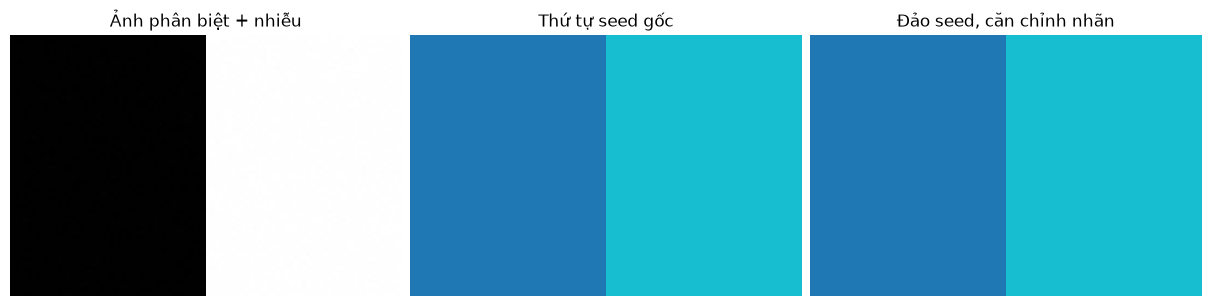

In [7]:
rng_b3 = np.random.default_rng(2026)
H3, W3 = 60, 90
img_b3 = np.where(np.indices((H3,W3))[1] < W3//2, 35.0, 220.0)
img_b3 += rng_b3.normal(0, 0.25, size=(H3,W3))
seeds_b3 = [(30,12), (30,78)]
labels_normal, _ = srg(img_b3, seeds_b3, connectivity=4, stale='lazy', tie='insertion')
labels_reverse, _ = srg(img_b3, seeds_b3[::-1], connectivity=4, stale='lazy', tie='insertion')
assert len(np.unique(img_b3)) > 100, 'B3 không được kiểm bằng ảnh phẳng'
b3_diff = int(np.count_nonzero(labels_normal != (1 - labels_reverse)))
assert np.array_equal(labels_normal == 0, labels_reverse == 1)
assert b3_diff == 0, f'B3 thất bại: {b3_diff} pixel'
print(f'B3 PASS: {b3_diff}/{img_b3.size} pixel khác sau hoán vị nhãn')
fig, ax = plt.subplots(1,3,figsize=(12,3.6),constrained_layout=True)
ax[0].imshow(img_b3,cmap='gray'); ax[0].set_title('Ảnh phân biệt + nhiễu')
ax[1].imshow(labels_normal,cmap='tab10',vmin=0,vmax=1); ax[1].set_title('Thứ tự seed gốc')
ax[2].imshow(1-labels_reverse,cmap='tab10',vmin=0,vmax=1); ax[2].set_title('Đảo seed, căn chỉnh nhãn')
for a in ax: a.axis('off')
plt.show()


## 4. B4 — SRG so với Classic có `order="stack"` (chờ mã gốc)


In [8]:
import importlib, inspect
khanh_mod = importlib.reload(importlib.import_module('khanh_region_growing'))
_raw_classic = khanh_mod.region_growing_classic
sig = inspect.signature(_raw_classic)
assert 'order' in sig.parameters, 'B4: hàm gốc phải hỗ trợ order=stack'

if 'connectivity' in sig.parameters:
    region_growing_classic = _raw_classic
else:
    def region_growing_classic(img, seeds, T, order='stack', connectivity=4):
        return _raw_classic(img, seeds, T, order=order)

HAS_CLASSIC = True
print('Đã tìm thấy Classic gốc: B4 và quét T sẽ chạy.')

Đã tìm thấy Classic gốc: B4 và quét T sẽ chạy.


B4 PASS: SRG khác Classic gốc 0/8800 pixel, T=8, order=stack.


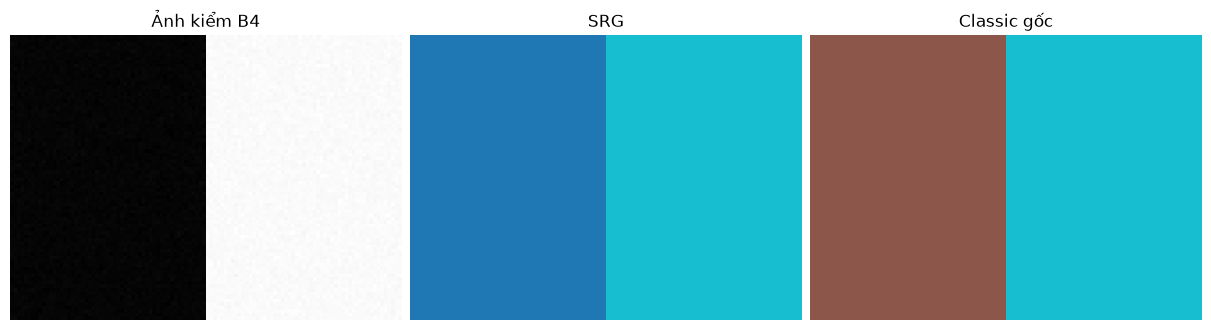

In [9]:
rng_b4 = np.random.default_rng(73)
H4,W4 = 80,110
img_b4 = np.where(np.indices((H4,W4))[1] < W4//2, 50., 200.)
img_b4 += rng_b4.normal(0, 1.0, size=img_b4.shape)
seeds_b4 = [(40,20),(40,90)]
labels_b4_srg, _ = srg(img_b4, seeds_b4, connectivity=4, stale='lazy')
if HAS_CLASSIC:
    raw_b4 = np.asarray(region_growing_classic(img_b4, seeds_b4, 8.0,
                                               connectivity=4, order='stack'))
    assert raw_b4.shape == labels_b4_srg.shape
    assert np.issubdtype(raw_b4.dtype, np.integer)
    original_codes = [int(raw_b4[r,c]) for r,c in seeds_b4]
    assert len(set(original_codes)) == 2, 'Hai seed Classic phải khác nhãn'
    other_codes = set(np.unique(raw_b4)) - set(original_codes) - {-1}
    assert not other_codes, f'Classic có nhãn không rõ quy ước: {other_codes}'
    labels_b4_classic = np.full(raw_b4.shape,-1,dtype=int)
    for i, code in enumerate(original_codes):
        labels_b4_classic[raw_b4 == code] = i
    assert all(labels_b4_classic[r,c] == i for i,(r,c) in enumerate(seeds_b4))
    diff_b4 = int(np.count_nonzero(labels_b4_srg != labels_b4_classic))
    assert 0 <= diff_b4 <= img_b4.size
    print(f'B4 PASS: SRG khác Classic gốc {diff_b4}/{img_b4.size} pixel, T=8, order=stack.')
    fig,ax=plt.subplots(1,3,figsize=(12,3.4),constrained_layout=True)
    ax[0].imshow(img_b4,cmap='gray');ax[0].set_title('Ảnh kiểm B4')
    ax[1].imshow(labels_b4_srg,cmap='tab10');ax[1].set_title('SRG')
    ax[2].imshow(labels_b4_classic,cmap='tab10',vmin=-1,vmax=1);ax[2].set_title('Classic gốc')
    for a in ax:a.axis('off')
    plt.show()
else:
    print('B4 SKIP (chưa đạt): chưa có mã Classic gốc. Không báo số pixel khác nhau.')


B5 PASS: biên chuyển nhãn ở cột [25] (tie=insertion).


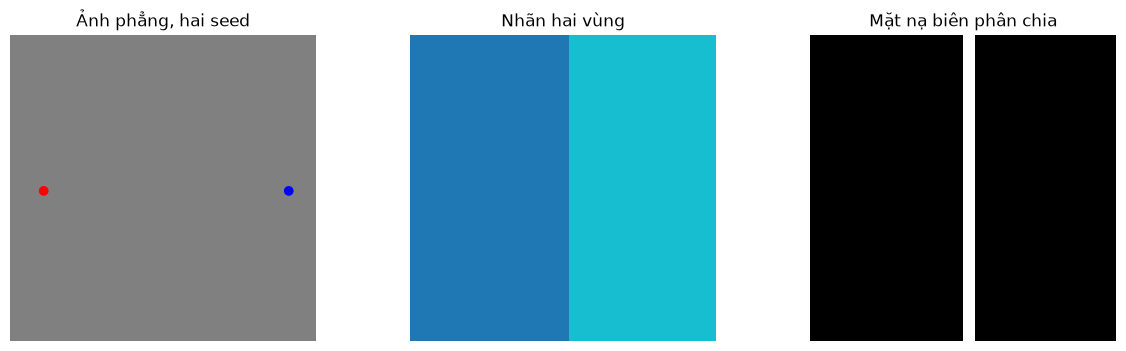

In [10]:
img_b5 = np.full((50,50),128,dtype=np.uint8)
seeds_b5 = [(25,5),(25,45)]
labels_b5,boundary_b5=srg(img_b5,seeds_b5,connectivity=4,stale='lazy',tie='insertion')
assert boundary_b5.any()
assert np.array_equal(boundary_b5,make_boundary_mask(labels_b5,4))
cuts_b5=[np.flatnonzero(labels_b5[r,:-1]!=labels_b5[r,1:]) for r in range(50)]
assert all(len(c)==1 for c in cuts_b5), 'Mỗi hàng cần một đường phân giới duy nhất'
cols_b5=np.unique(np.array([int(c[0]) for c in cuts_b5]))
assert np.all((cols_b5 >= 20) & (cols_b5 <= 30)), 'Biên không ở gần trục giữa'
print(f'B5 PASS: biên chuyển nhãn ở cột {cols_b5.tolist()} (tie=insertion).')
fig, ax=plt.subplots(1,3,figsize=(12,3.4),constrained_layout=True)
ax[0].imshow(img_b5,cmap='gray',vmin=0,vmax=255); ax[0].scatter([5,45],[25,25],c=['red','blue']);ax[0].set_title('Ảnh phẳng, hai seed')
ax[1].imshow(labels_b5,cmap='tab10',vmin=0,vmax=1);ax[1].set_title('Nhãn hai vùng')
ax[2].imshow(boundary_b5,cmap='gray');ax[2].set_title('Mặt nạ biên phân chia')
for a in ax:a.axis('off')
plt.show()


## 6. A1 — Lazy khác Frozen trên gradient

A1 PASS: Lazy khác Frozen 2600/40000 pixel.


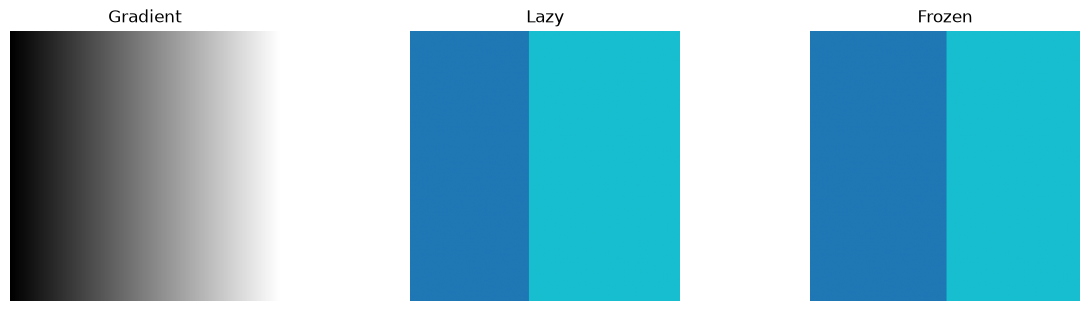

In [11]:
grad_img=np.tile(np.linspace(0,255,200,dtype=np.float64),(200,1))
grad_seeds=[(100,50),(100,150)]
lazy_lab,_=srg(grad_img,grad_seeds,stale='lazy',epsilon=1e-6)
frozen_lab,_=srg(grad_img,grad_seeds,stale='frozen',epsilon=1e-6)
diff_grad=int(np.count_nonzero(lazy_lab!=frozen_lab))
assert diff_grad>0,'Gradient phải cho ra kết quả khác nhau trên cấu hình test này'
print(f'A1 PASS: Lazy khác Frozen {diff_grad}/{grad_img.size} pixel.')
fig,ax=plt.subplots(1,3,figsize=(12,3),constrained_layout=True)
ax[0].imshow(grad_img,cmap='gray');ax[0].set_title('Gradient')
ax[1].imshow(lazy_lab,cmap='tab10');ax[1].set_title('Lazy')
ax[2].imshow(frozen_lab,cmap='tab10');ax[2].set_title('Frozen')
for a in ax:a.axis('off')
plt.show()


A1 PASS: Lazy khác Frozen 5200/40000 pixel.


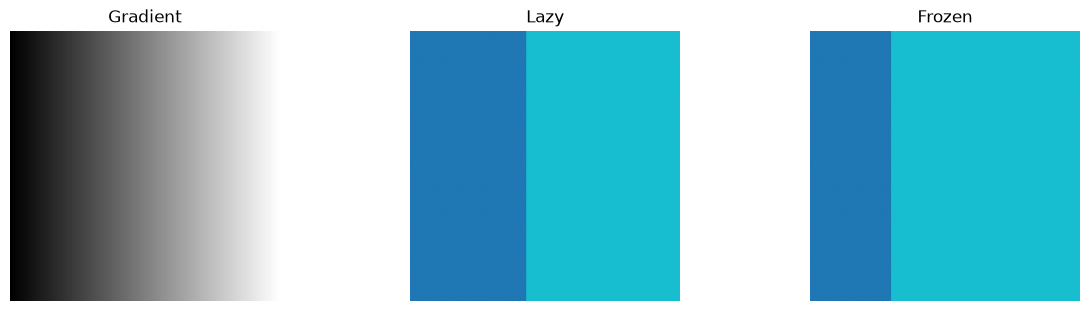

In [12]:
grad_img=np.tile(np.linspace(0,255,200,dtype=np.float64),(200,1))
grad_seeds=[(100,20),(100,100)]
lazy_lab,_=srg(grad_img,grad_seeds,stale='lazy',epsilon=1e-6)
frozen_lab,_=srg(grad_img,grad_seeds,stale='frozen',epsilon=1e-6)
diff_grad=int(np.count_nonzero(lazy_lab!=frozen_lab))
assert diff_grad>0,'Gradient phải cho ra kết quả khác nhau trên cấu hình test này'
print(f'A1 PASS: Lazy khác Frozen {diff_grad}/{grad_img.size} pixel.')
fig,ax=plt.subplots(1,3,figsize=(12,3),constrained_layout=True)
ax[0].imshow(grad_img,cmap='gray');ax[0].set_title('Gradient')
ax[1].imshow(lazy_lab,cmap='tab10');ax[1].set_title('Lazy')
ax[2].imshow(frozen_lab,cmap='tab10');ax[2].set_title('Frozen')
for a in ax:a.axis('off')
plt.show()


### Phân tích bằng chứng Gradient (`frozen` vs `lazy`) & Cơ chế thuật toán

1. **Vùng tràn biên & Nguyên nhân `frozen` tràn còn `lazy` không:**
   - **Khu vực tràn:** Vùng dải chuyển sắc mượt (gradient) ở giữa ảnh nơi cường độ sáng tăng dần đều từ trái sang phải.
   - **Chế độ `frozen`:** Giữ cố định trung bình vùng bằng giá trị tại seed ban đầu ($\mu = I(\text{seed})$). Khi vùng lan dọc theo dải dốc cường độ, miễn là độ chênh so với seed gốc chưa vượt ngưỡng $T$ ($|I(p) - \mu_{\text{seed}}| < T$), thuật toán tiếp tục kết nạp điểm mới, làm ranh giới bị đẩy tràn qua vùng trung gian.
   - **Chế độ `lazy`:** Cập nhật lại giá trị trung bình $\mu$ theo các điểm ảnh thực tế vừa kết nạp, giúp tiêu chuẩn đồng nhất bám sát cường độ cục bộ và phân tách biên chính xác hơn giữa hai vùng sáng - tối.

2. **Liên hệ hiện tượng với cập nhật trung bình vùng & Thứ tự `pop` hàng đợi:**
   - **Cập nhật trung bình vùng ($\mu$):** Quyết định độ trượt (drift) của ngưỡng đồng nhất; cập nhật liên tục giúp thích nghi biến thiên sáng nhẹ nhưng dễ trôi nếu $T$ lớn.
   - **Thứ tự `pop` khỏi hàng đợi ưu tiên (Priority Queue):** SRG luôn lấy ra điểm có độ lệch $|I(p) - \mu|$ nhỏ nhất để xét trước, giúp vùng phình đồng tâm từ lõi đồng nhất ra rìa biên và loại bỏ sự phụ thuộc thứ tự duyệt (LIFO/FIFO) của thuật toán cổ điển.

## 7. Quét ngưỡng T — phải dùng Classic thật
Không tạo `region_growing_classic_dummy`; chưa có mã thì không vẽ đường cong giả.

T: [5, 10, 15, 20, 25, 30, 35, 40, 45, 50] | Diện tích: [400, 721, 1124, 1521, 1845, 2247, 2644, 3044, 3367, 3764]


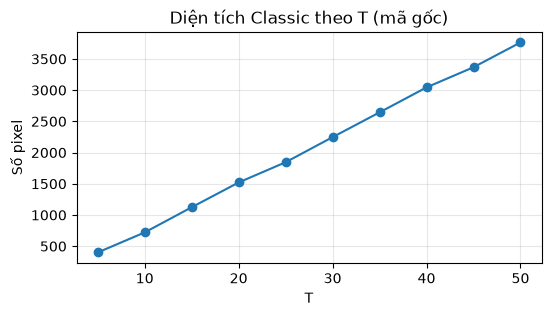

In [13]:
    if HAS_CLASSIC:
        Ts=[5,10,15,20,25,30,35,40,45,50]
        sizes=[]
        img_t=np.tile(np.linspace(0,255,120),(80,1))
        seeds_t=[(40,20)]
        for T in Ts:
            raw=np.asarray(region_growing_classic(img_t,seeds_t,T,
                                                  connectivity=4,order='stack'))
            assert raw.shape == img_t.shape
            assert np.issubdtype(raw.dtype,np.integer)
            sid=int(raw[seeds_t[0]])
            # Đếm các pixel có nhãn của seed gốc (chỉ một seed)
            sizes.append(int(np.count_nonzero(raw==sid)))
        assert all(0<=v<=img_t.size for v in sizes)
        print('T:',Ts,'| Diện tích:',sizes)
        plt.figure(figsize=(6,3));plt.plot(Ts,sizes,'o-');plt.title('Diện tích Classic theo T (mã gốc)');plt.xlabel('T');plt.ylabel('Số pixel');plt.grid(alpha=0.3);plt.show()
    else:
        print('QUÉT T CHƯA CHẠY: cần Classic gốc, không dùng hàm giả lập.')


## 8. Tiến trình SRG — 8 khung hình

8 khung: số pixel đã gán = [2, 687, 1373, 2058, 2744, 3429, 4115, 4800]


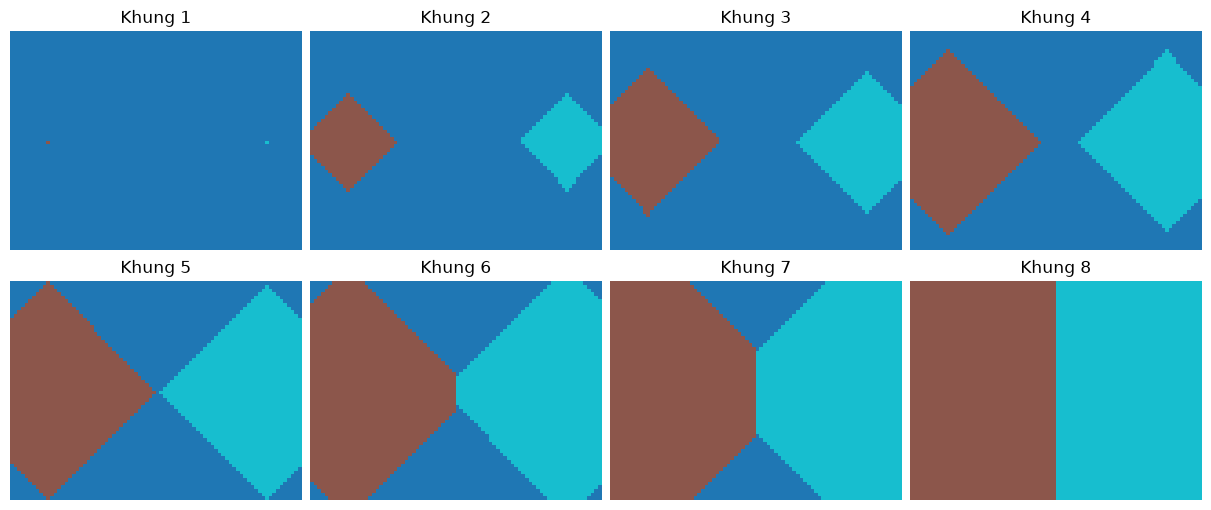

In [14]:
frame_img=np.where(np.indices((60,80))[1] < 40,35.0,210.0)
frame_seeds=[(30,10),(30,70)]
frames=srg_step_frames(frame_img,frame_seeds,n_frames=8)
assert len(frames)==8 and all(x.shape==frame_img.shape for x in frames)
assert np.count_nonzero(frames[0]>=0)==2
assert np.count_nonzero(frames[-1]<0)==0
print('8 khung: số pixel đã gán =', [int(np.count_nonzero(x>=0)) for x in frames])
fig,axs=plt.subplots(2,4,figsize=(12,5),constrained_layout=True)
for i,ax in enumerate(axs.flat):
    ax.imshow(frames[i],cmap='tab10',vmin=-1,vmax=1)
    ax.set_title(f'Khung {i+1}');ax.axis('off')
plt.show()


## 9. API `seed_sensitivity` cho thành viên Data Science
**seeds** = `[(row, col), ...]` tọa độ nguyên, đánh từ 0; **segment_fn(img, seeds)** trả duy nhất mảng nhãn nguyên `(H,W)` (không trả tuple `(labels, boundary)`). Chi tiết nằm trong `SPEC_SEED_SENSITIVITY.md`.

In [15]:
def segment_fn(img, seeds):
    labels, _ = srg(img, seeds, connectivity=4, stale='lazy',
                    tie='insertion', random_seed=42,epsilon=1e-6)
    return labels
test_api = np.tile(np.linspace(0,255,70),(40,1))
test_seeds = [(20,10),(20,60)]
labels_api=segment_fn(test_api,test_seeds)
assert labels_api.shape==test_api.shape
assert np.issubdtype(labels_api.dtype,np.integer)
assert all(labels_api[r,c]==i for i,(r,c) in enumerate(test_seeds))
print('SPEC PASS: segment_fn(img,seeds) -> labels (H,W), nhãn đúng theo thứ tự seed.')


SPEC PASS: segment_fn(img,seeds) -> labels (H,W), nhãn đúng theo thứ tự seed.
